<a href="https://colab.research.google.com/github/Ankurchatterjee-me/DataScienceProject/blob/main/SyntheticITMetrics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Libraries loaded successfully
Synthetic dataset created: 500 data points
            timestamp  cpu_usage  memory_usage  response_time_ms
0 2026-10-01 00:00:00  48.973713     69.261775        154.983886
1 2026-10-01 00:05:00  43.893886     79.094166        143.115842
2 2026-10-01 00:10:00  50.181508     46.014324        121.490759
3 2026-10-01 00:15:00  57.184239     65.629692        103.826581
4 2026-10-01 00:20:00  43.126773     53.493574        137.455583

Anomalies detected: 15


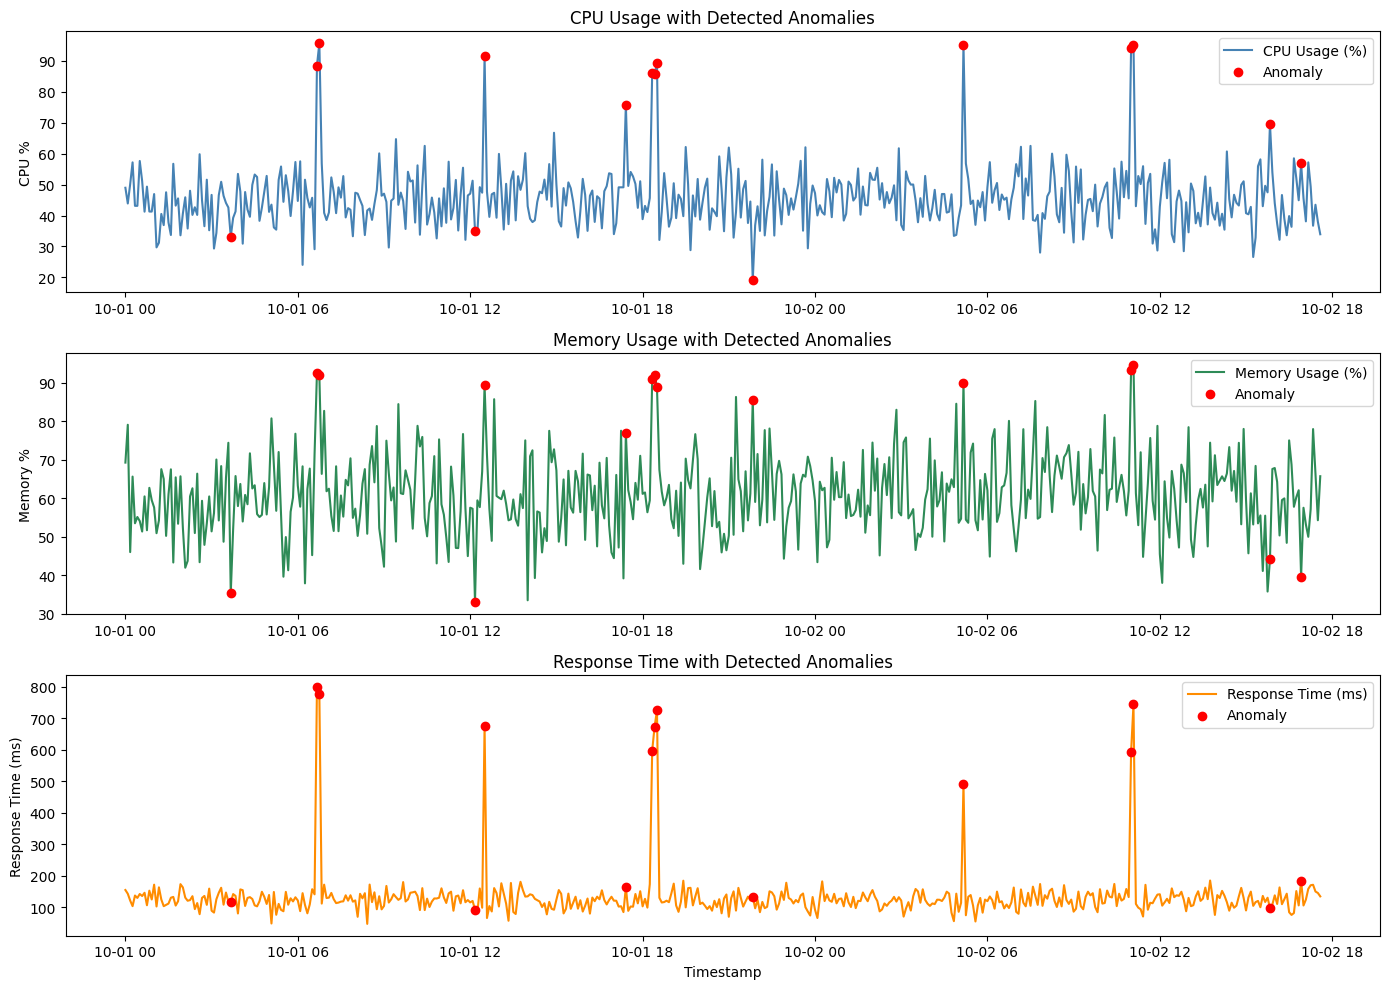


SUMMARY FOR PROJECT REPORT
Total data points analyzed : 500
Anomalies detected         : 15
Anomaly rate               : 3.0%

This demonstrates how AIOps platforms use machine learning
(Isolation Forest) to automatically detect abnormal patterns
in IT operations metrics such as CPU, memory, and response time.


In [1]:
# AIOps Synthetic Anomaly Detection Demo
# Project: Impact of AIOps in Modern Enterprises
# Purpose: Demonstrate how AIOps can detect anomalies in IT operations metrics

# ============================================
# 1. IMPORT LIBRARIES
# ============================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from datetime import datetime, timedelta

print("Libraries loaded successfully")

# ============================================
# 2. GENERATE SYNTHETIC IT OPERATIONS DATA
# ============================================
np.random.seed(42)
n_points = 500
timestamps = [datetime(2026, 10, 1) + timedelta(minutes=5*i) for i in range(n_points)]

# Normal baseline metrics
cpu = np.random.normal(45, 8, n_points)
memory = np.random.normal(60, 10, n_points)
response_time = np.random.normal(120, 25, n_points)

# Inject anomalies (spikes and drops typical in IT systems)
anomaly_indices = [80, 81, 150, 220, 221, 222, 350, 420, 421]

cpu[anomaly_indices] = np.random.uniform(85, 98, len(anomaly_indices))
memory[anomaly_indices] = np.random.uniform(88, 97, len(anomaly_indices))
response_time[anomaly_indices] = np.random.uniform(450, 800, len(anomaly_indices))

df = pd.DataFrame({
    'timestamp': timestamps,
    'cpu_usage': cpu,
    'memory_usage': memory,
    'response_time_ms': response_time
})

print(f"Synthetic dataset created: {len(df)} data points")
print(df.head())

# ============================================
# 3. ANOMALY DETECTION USING ISOLATION FOREST
# ============================================
features = ['cpu_usage', 'memory_usage', 'response_time_ms']
model = IsolationForest(contamination=0.03, random_state=42)
df['anomaly'] = model.fit_predict(df[features])
df['anomaly'] = df['anomaly'].map({1: 0, -1: 1})  # 1 = anomaly


anomalies = df[df['anomaly'] == 1]
print(f"\nAnomalies detected: {len(anomalies)}")

# ============================================
# 4. VISUALIZATION
# ============================================
plt.figure(figsize=(14, 10))

# CPU Usage
plt.subplot(3, 1, 1)
plt.plot(df['timestamp'], df['cpu_usage'], label='CPU Usage (%)', color='steelblue')
plt.scatter(anomalies['timestamp'], anomalies['cpu_usage'], color='red', label='Anomaly', zorder=5)
plt.title('CPU Usage with Detected Anomalies')
plt.ylabel('CPU %')
plt.legend()

# Memory Usage
plt.subplot(3, 1, 2)
plt.plot(df['timestamp'], df['memory_usage'], label='Memory Usage (%)', color='seagreen')
plt.scatter(anomalies['timestamp'], anomalies['memory_usage'], color='red', label='Anomaly', zorder=5)
plt.title('Memory Usage with Detected Anomalies')
plt.ylabel('Memory %')
plt.legend()

# Response Time
plt.subplot(3, 1, 3)
plt.plot(df['timestamp'], df['response_time_ms'], label='Response Time (ms)', color='darkorange')
plt.scatter(anomalies['timestamp'], anomalies['response_time_ms'], color='red', label='Anomaly', zorder=5)
plt.title('Response Time with Detected Anomalies')
plt.ylabel('Response Time (ms)')
plt.xlabel('Timestamp')
plt.legend()

plt.tight_layout()
plt.show()

# ============================================
# 5. SUMMARY FOR REPORT
# ============================================
print("\n" + "="*50)
print("SUMMARY FOR PROJECT REPORT")
print("="*50)
print(f"Total data points analyzed : {len(df)}")
print(f"Anomalies detected         : {len(anomalies)}")
print(f"Anomaly rate               : {len(anomalies)/len(df)*100:.1f}%")
print("\nThis demonstrates how AIOps platforms use machine learning")
print("(Isolation Forest) to automatically detect abnormal patterns")
print("in IT operations metrics such as CPU, memory, and response time.")